In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Rainfall notebook ready!")

Rainfall notebook ready!


In [3]:
rainfall_raw_path = (
    '/content/drive/MyDrive/MVJ_Internship/'
    'Project3/Day19_Clustering_Forecasting/'
    'Bengaluru_Rainfall_Forecasting/data/raw'
)

print(os.listdir(rainfall_raw_path))

['580edb55-4384-46c6-aeb8-2c21f3425d72.csv']


In [4]:
rainfall_csv_files = glob.glob(
    os.path.join(rainfall_raw_path, '*.csv')
)

print("CSV files found:", len(rainfall_csv_files))

for i, file in enumerate(rainfall_csv_files, start=1):
    print(i, os.path.basename(file))

CSV files found: 1
1 580edb55-4384-46c6-aeb8-2c21f3425d72.csv


In [5]:
if len(rainfall_csv_files) != 1:
    raise ValueError(
        "Please identify the correct rainfall CSV before loading."
    )

rainfall_file_path = rainfall_csv_files[0]

rainfall_df = pd.read_csv(rainfall_file_path)

print("Rainfall dataset loaded!")
print("Shape:", rainfall_df.shape)

Rainfall dataset loaded!
Shape: (127, 16)


In [6]:
display(rainfall_df.head(10))

,Year,Jan,Feb,Mar,Apr,May,June,July,Aug,Sept,Oct,Nov,Dec,Total,El NiNo (Y/N),La Nina (Y/N)
0,1901,0.0,78.9,0.0,24.3,146.0,47.7,71.6,71.6,318.5,120.3,37.3,23.1,939.3,Y,N
1,1902,0.7,0.0,17.0,58.1,197.8,62.2,32.0,79.5,213.6,219.9,11.1,25.4,917.3,N,N
2,1903,0.0,0.0,0.0,1.5,63.7,109.2,27.9,189.7,475.2,171.1,233.6,29.4,1301.3,Y,N
3,1904,0.5,0.0,0.0,14.4,241.5,49.5,149.3,53.8,126.4,157.2,0.0,1.7,794.3,N,Y
4,1905,1.7,0.0,56.6,32.7,90.6,60.7,58.9,266.4,62.4,227.8,29.2,3.0,890.0,N,N
5,1906,2.7,23.6,15.2,2.2,34.0,97.0,160.5,268.2,199.8,162.8,16.5,29.2,1011.7,Y,N
6,1907,24.1,0.0,31.7,109.9,48.7,113.2,205.7,24.3,176.2,27.6,27.6,12.4,801.4,N,N
7,1908,101.8,0.0,1.5,18.2,182.8,32.0,104.6,35.5,113.5,58.9,1.7,4.3,654.8,N,N
8,1909,16.0,0.0,0.0,127.0,200.9,10.4,39.8,309.3,130.8,159.7,12.1,0.0,1006.0,N,Y
9,1910,0.0,0.0,0.2,5.0,29.7,57.6,265.1,256.0,157.4,273.0,125.9,0.0,1169.9,N,Y


In [7]:
display(rainfall_df.tail(10))

,Year,Jan,Feb,Mar,Apr,May,June,July,Aug,Sept,Oct,Nov,Dec,Total,El NiNo (Y/N),La Nina (Y/N)
117,2018,0.0,1.8,47.6,34.1,140.4,29.5,94.2,70.9,106.9,63.3,12.8,16.2,617.7,N,N
118,2019,0.8,58.0,0.0,41.2,136.7,58.4,93.9,142.8,211.4,196.3,8.0,12.6,960.1,N,N
119,2020,0.0,0.0,18.4,121.1,128.6,114.8,158.3,75.9,300.0,204.3,71.0,20.4,1212.8,N,N
120,2021,21.2,10.3,0.0,118.2,130.7,91.1,203.3,98.3,188.5,366.3,277.8,5.4,1511.1,N,Y
121,2022,3.9,0.0,0.0,61.4,270.2,255.5,136.7,378.7,353.0,296.5,59.8,74.7,1957.7,N,Y
122,2023,0.0,0.0,8.4,28.2,305.5,72.3,141.5,12.6,248.4,96.0,106.6,0.7,1020.2,Y,N
123,2024,0.0,0.0,0.0,0.0,180.9,204.7,92.8,230.2,23.9,306.2,21.6,93.7,1154.0,Y,Y
124,2025,5.2,0.0,11.8,32.3,315.0,58.0,87.5,161.8,242.0,127.9,2.3,1.2,1045.0,Y,Y
125,LPA (1991-2020),1.7,5.9,19.2,73.0,133.0,111.0,112.8,160.2,198.4,180.7,63.4,14.8,1077.1,NaN,NaN
126,LPA (1981-2010),1.9,5.2,18.0,55.7,112.6,104.3,116.2,149.4,213.8,166.7,48.5,16.8,986.1,NaN,NaN


In [8]:
print("Rainfall columns:")
print(rainfall_df.columns.tolist())

Rainfall columns:
['Year', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'June', 'July', 'Aug', 'Sept', 'Oct', 'Nov', 'Dec', 'Total', 'El NiNo (Y/N)', 'La Nina (Y/N)']


In [9]:
rainfall_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 127 entries, 0 to 126
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Year           127 non-null    object 
 1   Jan            127 non-null    float64
 2   Feb            127 non-null    float64
 3   Mar            127 non-null    float64
 4   Apr            127 non-null    float64
 5   May            127 non-null    float64
 6   June           127 non-null    float64
 7   July           127 non-null    float64
 8   Aug            127 non-null    float64
 9   Sept           127 non-null    float64
 10  Oct            127 non-null    float64
 11  Nov            127 non-null    float64
 12  Dec            126 non-null    float64
 13  Total          127 non-null    float64
 14  El NiNo (Y/N)  125 non-null    object 
 15  La Nina (Y/N)  125 non-null    object 
dtypes: float64(13), object(3)
memory usage: 16.0+ KB


In [10]:
print("Missing values:")
print(rainfall_df.isnull().sum())

Missing values:
Year             0
Jan              0
Feb              0
Mar              0
Apr              0
May              0
June             0
July             0
Aug              0
Sept             0
Oct              0
Nov              0
Dec              1
Total            0
El NiNo (Y/N)    2
La Nina (Y/N)    2
dtype: int64


In [11]:
#generate a numerical summary

display(rainfall_df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Year,127,127,1901,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jan,127.0,NaN,NaN,NaN,4.324409,10.812623,0.0,0.0,0.0,4.2,101.8
Feb,127.0,NaN,NaN,NaN,7.351181,17.125952,0.0,0.0,0.0,4.55,89.9
Mar,127.0,NaN,NaN,NaN,11.599213,20.871647,0.0,0.0,1.5,15.2,115.4
Apr,127.0,NaN,NaN,NaN,50.126772,51.703063,0.0,13.45,32.2,75.0,323.8
May,127.0,NaN,NaN,NaN,119.982677,60.069905,1.3,76.05,112.1,154.2,315.0
June,127.0,NaN,NaN,NaN,84.94252,50.282626,4.5,55.85,75.7,106.75,255.5
July,127.0,NaN,NaN,NaN,110.962992,61.725898,18.5,67.6,100.9,141.2,350.2
Aug,127.0,NaN,NaN,NaN,140.323622,84.777969,12.6,75.25,121.1,177.5,387.1
Sept,127.0,NaN,NaN,NaN,187.85748,105.362578,8.3,106.5,176.2,242.65,516.6


In [12]:
#create a working copy

rainfall_working = rainfall_df.copy()

print("Working copy created!")
print("Shape:", rainfall_working.shape)

Working copy created!
Shape: (127, 16)


In [13]:
#inspect the possible date and rainfall columns

for column in rainfall_working.columns:
    print("\nColumn:", column)
    print("Data type:", rainfall_working[column].dtype)
    print("Sample values:")
    print(rainfall_working[column].dropna().head(8).tolist())


Column: Year
Data type: object
Sample values:
['1901', '1902', '1903', '1904', '1905', '1906', '1907', '1908']

Column: Jan
Data type: float64
Sample values:
[0.0, 0.7, 0.0, 0.5, 1.7, 2.7, 24.1, 101.8]

Column: Feb
Data type: float64
Sample values:
[78.9, 0.0, 0.0, 0.0, 0.0, 23.6, 0.0, 0.0]

Column: Mar
Data type: float64
Sample values:
[0.0, 17.0, 0.0, 0.0, 56.6, 15.2, 31.7, 1.5]

Column: Apr
Data type: float64
Sample values:
[24.3, 58.1, 1.5, 14.4, 32.7, 2.2, 109.9, 18.2]

Column: May
Data type: float64
Sample values:
[146.0, 197.8, 63.7, 241.5, 90.6, 34.0, 48.7, 182.8]

Column: June
Data type: float64
Sample values:
[47.7, 62.2, 109.2, 49.5, 60.7, 97.0, 113.2, 32.0]

Column: July
Data type: float64
Sample values:
[71.6, 32.0, 27.9, 149.3, 58.9, 160.5, 205.7, 104.6]

Column: Aug
Data type: float64
Sample values:
[71.6, 79.5, 189.7, 53.8, 266.4, 268.2, 24.3, 35.5]

Column: Sept
Data type: float64
Sample values:
[318.5, 213.6, 475.2, 126.4, 62.4, 199.8, 176.2, 113.5]

Column: Oct
Data

In [14]:
for column in rainfall_working.columns:
    print("\nColumn name:", column)
    print("Data type:", rainfall_working[column].dtype)
    print("Sample values:")
    print(rainfall_working[column].dropna().head(10).tolist())


Column name: Year
Data type: object
Sample values:
['1901', '1902', '1903', '1904', '1905', '1906', '1907', '1908', '1909', '1910']

Column name: Jan
Data type: float64
Sample values:
[0.0, 0.7, 0.0, 0.5, 1.7, 2.7, 24.1, 101.8, 16.0, 0.0]

Column name: Feb
Data type: float64
Sample values:
[78.9, 0.0, 0.0, 0.0, 0.0, 23.6, 0.0, 0.0, 0.0, 0.0]

Column name: Mar
Data type: float64
Sample values:
[0.0, 17.0, 0.0, 0.0, 56.6, 15.2, 31.7, 1.5, 0.0, 0.2]

Column name: Apr
Data type: float64
Sample values:
[24.3, 58.1, 1.5, 14.4, 32.7, 2.2, 109.9, 18.2, 127.0, 5.0]

Column name: May
Data type: float64
Sample values:
[146.0, 197.8, 63.7, 241.5, 90.6, 34.0, 48.7, 182.8, 200.9, 29.7]

Column name: June
Data type: float64
Sample values:
[47.7, 62.2, 109.2, 49.5, 60.7, 97.0, 113.2, 32.0, 10.4, 57.6]

Column name: July
Data type: float64
Sample values:
[71.6, 32.0, 27.9, 149.3, 58.9, 160.5, 205.7, 104.6, 39.8, 265.1]

Column name: Aug
Data type: float64
Sample values:
[71.6, 79.5, 189.7, 53.8, 266.4

In [15]:
#check the date range

date_column = "Year"

rainfall_working[date_column] = pd.to_datetime(
    rainfall_working[date_column],
    errors="coerce"
)

print("Earliest date:", rainfall_working[date_column].min())
print("Latest date:", rainfall_working[date_column].max())

Earliest date: 1901-01-01 00:00:00
Latest date: 2025-01-01 00:00:00


In [16]:
print(
    "Invalid or missing dates:",
    rainfall_working[date_column].isna().sum()
)

Invalid or missing dates: 2


In [17]:
#sort the data chronologically

rainfall_working = rainfall_working.sort_values(
    by=date_column
).reset_index(drop=True)

display(rainfall_working.head())

,Year,Jan,Feb,Mar,Apr,May,June,July,Aug,Sept,Oct,Nov,Dec,Total,El NiNo (Y/N),La Nina (Y/N)
0,1901-01-01,0.0,78.9,0.0,24.3,146.0,47.7,71.6,71.6,318.5,120.3,37.3,23.1,939.3,Y,N
1,1902-01-01,0.7,0.0,17.0,58.1,197.8,62.2,32.0,79.5,213.6,219.9,11.1,25.4,917.3,N,N
2,1903-01-01,0.0,0.0,0.0,1.5,63.7,109.2,27.9,189.7,475.2,171.1,233.6,29.4,1301.3,Y,N
3,1904-01-01,0.5,0.0,0.0,14.4,241.5,49.5,149.3,53.8,126.4,157.2,0.0,1.7,794.3,N,Y
4,1905-01-01,1.7,0.0,56.6,32.7,90.6,60.7,58.9,266.4,62.4,227.8,29.2,3.0,890.0,N,N


In [18]:
#save the rainfall inspection report

rainfall_inspection = pd.DataFrame({
    "Column": rainfall_working.columns,
    "Data_Type": rainfall_working.dtypes.astype(str).values,
    "Missing_Values": rainfall_working.isnull().sum().values,
    "Unique_Values": rainfall_working.nunique(dropna=False).values
})

rainfall_processed_path = (
    '/content/drive/MyDrive/MVJ_Internship/'
    'Project3/Day19_Clustering_Forecasting/'
    'Bengaluru_Rainfall_Forecasting/data/processed'
)

os.makedirs(rainfall_processed_path, exist_ok=True)

rainfall_inspection.to_csv(
    os.path.join(
        rainfall_processed_path,
        'rainfall_inspection_report.csv'
    ),
    index=False
)

print("Rainfall inspection report saved!")

Rainfall inspection report saved!


In [19]:
 #identify the rainfall measurement column

print("Numeric columns:")
print(
    rainfall_working.select_dtypes(
        include=np.number
    ).columns.tolist()
)

display(rainfall_working.head())

Numeric columns:
['Jan', 'Feb', 'Mar', 'Apr', 'May', 'June', 'July', 'Aug', 'Sept', 'Oct', 'Nov', 'Dec', 'Total']


,Year,Jan,Feb,Mar,Apr,May,June,July,Aug,Sept,Oct,Nov,Dec,Total,El NiNo (Y/N),La Nina (Y/N)
0,1901-01-01,0.0,78.9,0.0,24.3,146.0,47.7,71.6,71.6,318.5,120.3,37.3,23.1,939.3,Y,N
1,1902-01-01,0.7,0.0,17.0,58.1,197.8,62.2,32.0,79.5,213.6,219.9,11.1,25.4,917.3,N,N
2,1903-01-01,0.0,0.0,0.0,1.5,63.7,109.2,27.9,189.7,475.2,171.1,233.6,29.4,1301.3,Y,N
3,1904-01-01,0.5,0.0,0.0,14.4,241.5,49.5,149.3,53.8,126.4,157.2,0.0,1.7,794.3,N,Y
4,1905-01-01,1.7,0.0,56.6,32.7,90.6,60.7,58.9,266.4,62.4,227.8,29.2,3.0,890.0,N,N


In [20]:
#set the rainfall column

rainfall_column = "Total"

assert rainfall_column in rainfall_working.columns, (
    "Rainfall column not found!"
)

print("Selected rainfall column:", rainfall_column)

Selected rainfall column: Total


In [21]:
#create a clean working time-series dataset

time_series_df = rainfall_working[
    [date_column, rainfall_column]
].copy()

time_series_df[rainfall_column] = pd.to_numeric(
    time_series_df[rainfall_column],
    errors="coerce"
)

time_series_df = time_series_df.dropna(
    subset=[date_column, rainfall_column]
)

time_series_df = time_series_df.sort_values(
    date_column
).reset_index(drop=True)

display(time_series_df.head())
print("Shape:", time_series_df.shape)

,Year,Total
0,1901-01-01,939.3
1,1902-01-01,917.3
2,1903-01-01,1301.3
3,1904-01-01,794.3
4,1905-01-01,890.0


Shape: (125, 2)


In [22]:
#check the rainfall values

print(time_series_df[rainfall_column].describe())

print(
    "Negative rainfall values:",
    (time_series_df[rainfall_column] < 0).sum()
)

count     125.000000
mean      960.949600
std       231.373813
min       543.800000
25%       795.300000
50%       950.300000
75%      1090.100000
max      1957.700000
Name: Total, dtype: float64
Negative rainfall values: 0


In [23]:
#check duplicate dates

duplicate_dates = time_series_df[
    time_series_df.duplicated(
        subset=[date_column],
        keep=False
    )
]

print("Rows with duplicate dates:", len(duplicate_dates))
display(duplicate_dates.head(10))

Rows with duplicate dates: 0


,Year,Total


In [24]:
#set the date as the index

time_series_df = time_series_df.set_index(date_column)

time_series_df = time_series_df.sort_index()

print("Time-series index created!")
display(time_series_df.head())

Time-series index created!


,Total
Year,
1901-01-01,939.3
1902-01-01,917.3
1903-01-01,1301.3
1904-01-01,794.3
1905-01-01,890.0


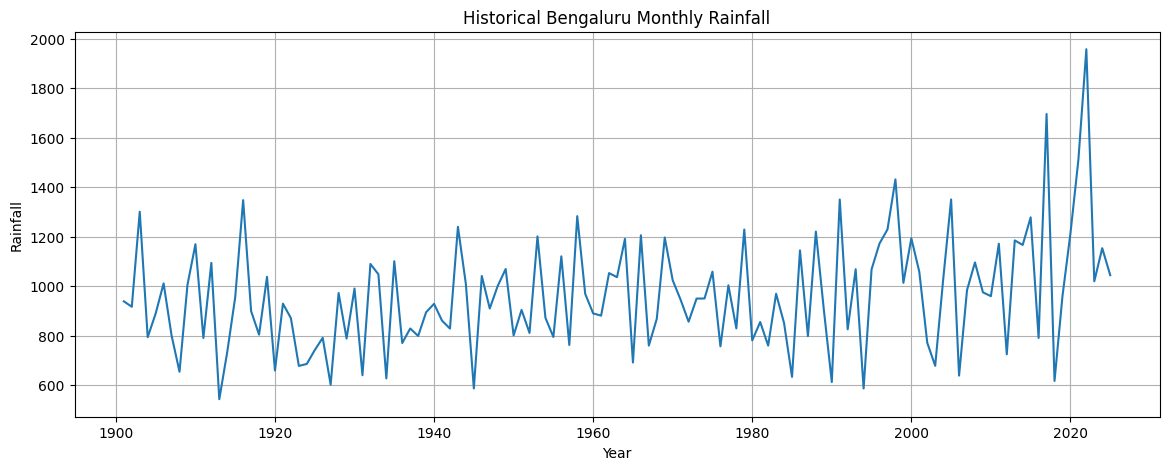

In [25]:
#plot historical rainfall

plt.figure(figsize=(14, 5))

plt.plot(
    time_series_df.index,
    time_series_df[rainfall_column]
)

plt.title("Historical Bengaluru Monthly Rainfall")
plt.xlabel("Year")
plt.ylabel("Rainfall")
plt.grid(True)
plt.show()

In [26]:
#calculate the 3 month moving-average

time_series_df["Moving_Average_3M"] = (
    time_series_df[rainfall_column]
    .rolling(window=3)
    .mean()
)

display(time_series_df.head(10))

,Total,Moving_Average_3M
Year,,
1901-01-01,939.3,NaN
1902-01-01,917.3,NaN
1903-01-01,1301.3,1052.633333
1904-01-01,794.3,1004.300000
1905-01-01,890.0,995.200000
1906-01-01,1011.7,898.666667
1907-01-01,801.4,901.033333
1908-01-01,654.8,822.633333
1909-01-01,1006.0,820.733333


In [27]:
#calculate the 12-month moving average

time_series_df["Moving_Average_12M"] = (
    time_series_df[rainfall_column]
    .rolling(window=12)
    .mean()
)

display(time_series_df.tail(15))

,Total,Moving_Average_3M,Moving_Average_12M
Year,,,
2011-01-01,1172.0,1035.900000,992.316667
2012-01-01,725.2,952.433333,953.258333
2013-01-01,1185.4,1027.533333,963.833333
2014-01-01,1167.0,1025.866667,996.750000
2015-01-01,1278.6,1210.333333,1046.741667
2016-01-01,791.4,1079.000000,1027.183333
2017-01-01,1696.0,1255.333333,1055.950000
2018-01-01,617.7,1035.033333,1054.166667
2019-01-01,960.1,1091.266667,1052.125000


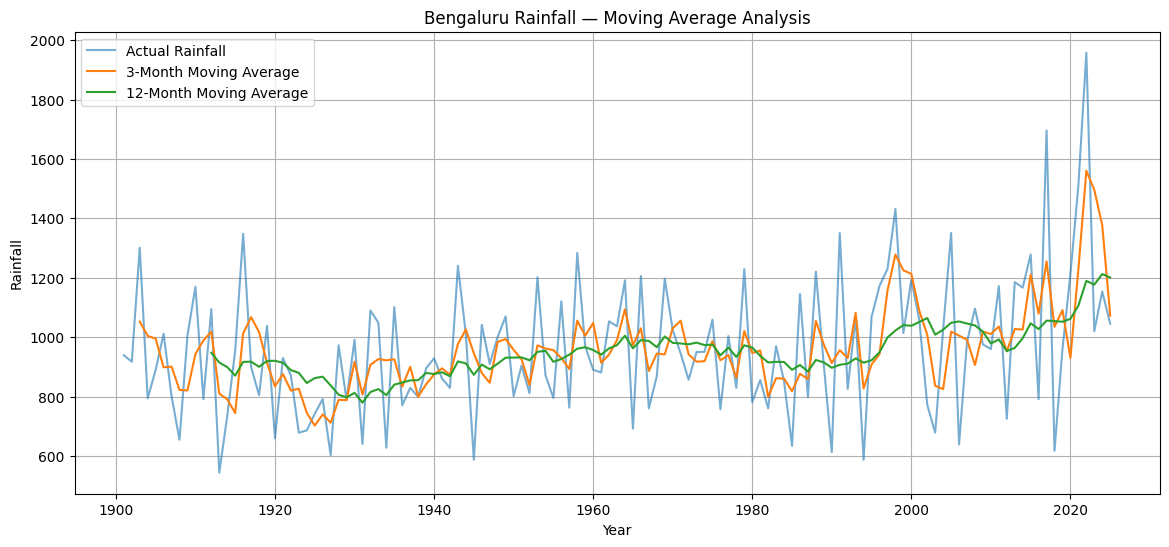

In [28]:
#plot actual rainfall and moving averages

plt.figure(figsize=(14, 6))

plt.plot(
    time_series_df.index,
    time_series_df[rainfall_column],
    label="Actual Rainfall",
    alpha=0.6
)

plt.plot(
    time_series_df.index,
    time_series_df["Moving_Average_3M"],
    label="3-Month Moving Average"
)

plt.plot(
    time_series_df.index,
    time_series_df["Moving_Average_12M"],
    label="12-Month Moving Average"
)

plt.title("Bengaluru Rainfall — Moving Average Analysis")
plt.xlabel("Year")
plt.ylabel("Rainfall")
plt.legend()
plt.grid(True)
plt.show()

In [29]:
#prepare training and testing tdata

rainfall_series = time_series_df[rainfall_column].astype(float)

if len(rainfall_series) <= 24:
    raise ValueError(
        "Not enough observations for a 12-month test period."
    )

train = rainfall_series.iloc[:-12]
test = rainfall_series.iloc[-12:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Test period:", test.index.min(), "to", test.index.max())

Training observations: 113
Testing observations: 12
Test period: 2014-01-01 00:00:00 to 2025-01-01 00:00:00


In [30]:
#create a moving-average forecast baseline

moving_average_forecast = pd.Series(
    train.tail(12).mean(),
    index=test.index
)

print("Moving-average forecast:")
display(moving_average_forecast)

Moving-average forecast:


,0
Year,
2014-01-01,963.833333
2015-01-01,963.833333
2016-01-01,963.833333
2017-01-01,963.833333
2018-01-01,963.833333
2019-01-01,963.833333
2020-01-01,963.833333
2021-01-01,963.833333
2022-01-01,963.833333


In [31]:
#train the smoothing model

from statsmodels.tsa.holtwinters import SimpleExpSmoothing

ses_model = SimpleExpSmoothing(
    train,
    initialization_method="estimated"
)

ses_fitted = ses_model.fit(
    optimized=True
)

exponential_forecast = ses_fitted.forecast(
    len(test)
)

print("Estimated smoothing level (alpha):", ses_fitted.params["smoothing_level"])
display(exponential_forecast)

Estimated smoothing level (alpha): 0.02933658928569357


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)


,0
2014-01-01,969.055646
2015-01-01,969.055646
2016-01-01,969.055646
2017-01-01,969.055646
2018-01-01,969.055646
2019-01-01,969.055646
2020-01-01,969.055646
2021-01-01,969.055646
2022-01-01,969.055646
2023-01-01,969.055646


In [32]:
#compare forecast errors

from sklearn.metrics import mean_absolute_error, mean_squared_error

mae_moving = mean_absolute_error(
    test,
    moving_average_forecast
)

rmse_moving = np.sqrt(
    mean_squared_error(test, moving_average_forecast)
)

mae_exp = mean_absolute_error(
    test,
    exponential_forecast
)

rmse_exp = np.sqrt(
    mean_squared_error(test, exponential_forecast)
)

forecast_comparison = pd.DataFrame({
    "Model": [
        "12-Month Moving Average Baseline",
        "Simple Exponential Smoothing"
    ],
    "MAE": [
        mae_moving,
        mae_exp
    ],
    "RMSE": [
        rmse_moving,
        rmse_exp
    ]
})

display(forecast_comparison.round(2))

,Model,MAE,RMSE
0,12-Month Moving Average Baseline,324.18,430.23
1,Simple Exponential Smoothing,321.57,427.37


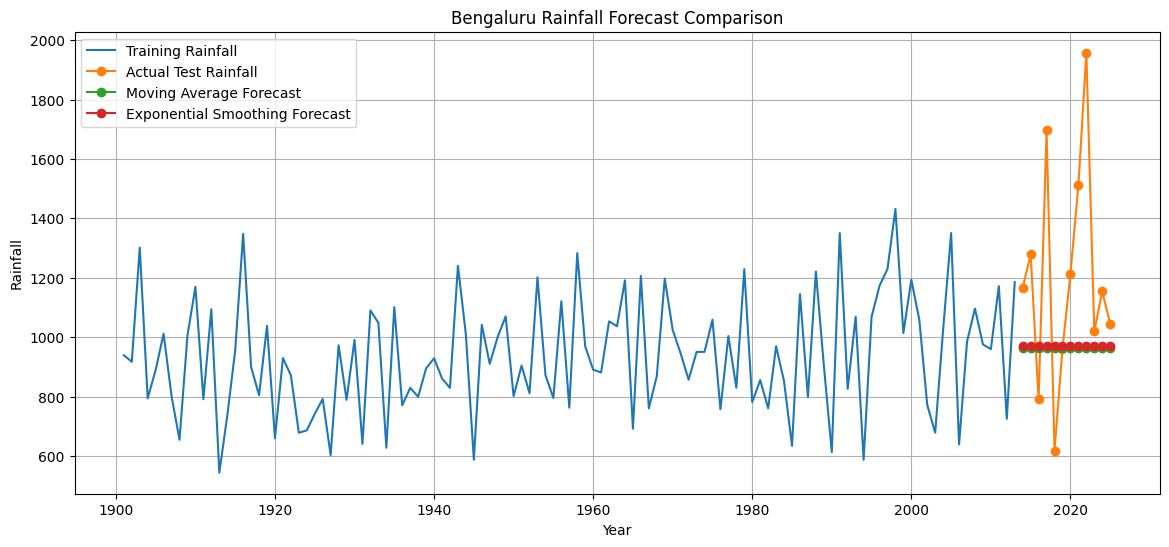

In [33]:
#plot and save the forecasting results

plt.figure(figsize=(14, 6))

plt.plot(
    train.index,
    train,
    label="Training Rainfall"
)

plt.plot(
    test.index,
    test,
    label="Actual Test Rainfall",
    marker="o"
)

plt.plot(
    test.index,
    moving_average_forecast,
    label="Moving Average Forecast",
    marker="o"
)

plt.plot(
    test.index,
    exponential_forecast,
    label="Exponential Smoothing Forecast",
    marker="o"
)

plt.title("Bengaluru Rainfall Forecast Comparison")
plt.xlabel("Year")
plt.ylabel("Rainfall")
plt.legend()
plt.grid(True)
plt.show()

In [34]:
#save the prepared data and comparision

time_series_df.to_csv(
    os.path.join(
        rainfall_processed_path,
        "bengaluru_rainfall_moving_averages.csv"
    )
)

forecast_results = pd.DataFrame({
    "Date": test.index,
    "Actual_Rainfall": test.values,
    "Moving_Average_Forecast": moving_average_forecast.values,
    "Exponential_Smoothing_Forecast": exponential_forecast.values
})

forecast_results.to_csv(
    os.path.join(
        rainfall_processed_path,
        "bengaluru_rainfall_forecast_results.csv"
    ),
    index=False
)

forecast_comparison.to_csv(
    os.path.join(
        rainfall_processed_path,
        "rainfall_model_comparison.csv"
    ),
    index=False
)

print("Rainfall forecasting outputs saved successfully!")

Rainfall forecasting outputs saved successfully!


## Rainfall Forecasting — Findings

1. **Historical rainfall pattern**:
The historical annual rainfall in Bengaluru shows a highly volatile fluctuation over the years, spanning from a minimum of 543.8 mm to a historic peak of 1957.7 mm (observed around 2022). There is a visible upward trend in both mean rainfall and peak volatility starting from the late 20th century onwards.

2. **Observation from the 3-month moving average**:
Since the time-series is built on annual entries representing yearly totals, the 3-period (3-Year) moving average smooths out short-term annual spikes and highlights medium-term cyclical peaks and troughs (e.g., highlighting dry spells in the early 1920s and late 1980s, alongside wet intervals around the late 1990s and 2020s).

3. **Observation from the 12-month moving average**:
The 12-period (12-Year) moving average filters out high-frequency fluctuations, clearly illustrating a long-term transition. It shows that Bengaluru's baseline rainfall remained relatively stable or slightly declined during the middle of the 20th century but has experienced a steady upward climb since roughly the year 2000.

4. **Moving average model MAE and RMSE**:
* **MAE**: 324.18 mm
* **RMSE**: 430.23 mm

5. **Exponential smoothing MAE and RMSE**:
* **MAE**: 321.57 mm
* **RMSE**: 427.37 mm

6. **Better-performing model on the test period**:
**Simple Exponential Smoothing (SES)** performed slightly better than the 12-Month Moving Average Baseline, yielding both a lower MAE (321.57 vs 324.18) and a lower RMSE (427.37 vs 430.23).

7. **Key observation**:
Both baseline models essentially predict flat lines around the long-term mean (approx. 963-969 mm), failing to capture the extreme year-to-year variation present in the test set (which includes dry years of ~617 mm and extremely wet years up to ~1957.7 mm). For highly volatile, non-stationary climate series, more advanced models (such as ARIMA/SARIMA with trends or machine learning models utilizing external climate drivers like El Niño / La Niña signals) would be recommended to capture year-to-year swings.

## Forecast Uncertainty

- Rainfall varies considerably across months and years.
- Historical averages cannot guarantee future rainfall.
- Unexpected weather conditions can cause large deviations.
- The forecast is evaluated on a limited historical test period.
- Forecast errors indicate that predictions are not exact.

The forecasts should be treated as estimates rather than
guaranteed future rainfall values.

## Model Limitations

Simple exponential smoothing does not explicitly model
seasonality or long-term trends.

Bengaluru rainfall has seasonal variation, so a more
advanced seasonal forecasting model may be useful in
future work.

The model comparison only tells us which method performed
better on the selected test period.

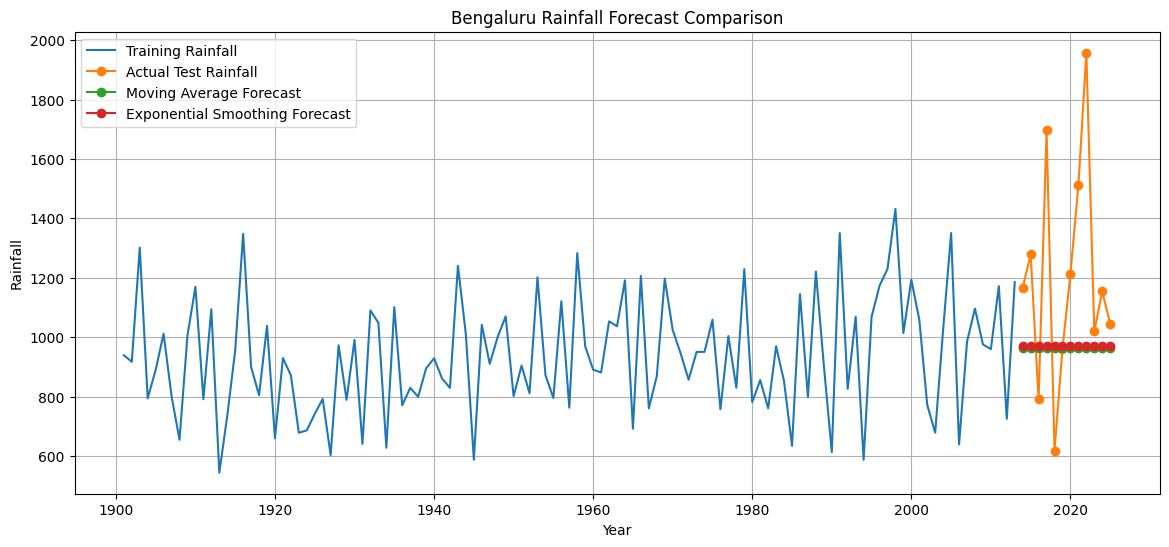

In [36]:
#save the forecasat comparision chart

plt.figure(figsize=(14, 6))

plt.plot(train.index, train, label="Training Rainfall")
plt.plot(test.index, test, label="Actual Test Rainfall", marker="o")
plt.plot(
    test.index,
    moving_average_forecast,
    label="Moving Average Forecast",
    marker="o"
)
plt.plot(
    test.index,
    exponential_forecast,
    label="Exponential Smoothing Forecast",
    marker="o"
)

plt.title("Bengaluru Rainfall Forecast Comparison")
plt.xlabel("Year")
plt.ylabel("Rainfall")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        rainfall_processed_path,
        "rainfall_forecast_comparison.png"
    ),
    bbox_inches="tight"
)

plt.show()

In [37]:
print("Rainfall processed files:")

for file in os.listdir(rainfall_processed_path):
    print(file)

Rainfall processed files:
rainfall_inspection_report.csv
bengaluru_rainfall_moving_averages.csv
bengaluru_rainfall_forecast_results.csv
rainfall_model_comparison.csv
rainfall_forecast_comparison.png
